# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zilionis 2019's NSCLC malignant manifold is **non-branching**. The honest branching test is run
here and read off the embedding, not a single metric: (i) a **PPT tree** over this compact
~3.9k-cell cloud throws a spray of **13–18 spurious forks** across every `Nodes`×`λ` combination
(a bush, not a clean Y); (ii) there is **no Gast/pSom co-expression hub** — cells high in *both*
modules are *depleted* (co-high enrichment ≈ 0.73 < 1), so Gast and pSom are mutually exclusive
rather than converging; (iii) the embedding is roundish (major/minor axis ≈ 1.05), not a
strip-with-a-branch. What is present is **organized Gast↔pSom cross-repression** (smoothed
r ≈ −0.58) with an **inverse/interior neural-crest gradient** — the §1 (Wu 2021) non-branching
case. The correct topology is therefore a **principal curve** (ElPiGraph, non-branching by
construction) fit on the *joint* embedding — **not** a re-embedding (re-embedding an anisotropic
compartment fabricates folds). The curve is rooted at the Gast/pSom-high tip and pseudotime flows
to the pSom-leaning / Crest end. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
import re
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the shared
**union** control pool and graph-smoothed (`_sm`) to read geography rather than inDrop per-cell
dropout. Raw per-cell scores are retained for the deliverable panels in 03.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,sv,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {sv[0]/sv[1]:.2f} (>~2 elongated)')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 3920 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.06 (>~2 elongated)
Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present
raw module means (honest readout): {'Gast': -0.0092, 'pSom': 0.0386, 'Crest': -0.0225}


### Honest branching test — PPT tree topology + co-expression hub
A genuine bifurcation would give a PPT tree with ~1 robust fork (3 tips) and a Gast/pSom co-high
**hub** (enrichment > 1). Here PPT throws **13–18 forks** at every setting (spurious over a compact
roundish cloud) and the co-high enrichment is **< 1** (mutual exclusivity, no hub) — so the manifold
is non-branching. Cross-repression is read from the smoothed spatial correlations.

In [4]:
def topo(ad):
    B = np.asarray(ad.uns['graph']['B']); deg = (B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT tree topology sweep (use_rep=X_umap) — forks should be ~1 for a true Y:')
for Nn in [100,150,200]:
    for lam in [1.0,3.0,10.0]:
        a2 = adata.copy()
        with contextlib.redirect_stdout(io.StringIO()):
            scf.tl.tree(a2, method='ppt', Nodes=Nn, ppt_lambda=lam, ppt_sigma=0.5, use_rep='X_umap', seed=SEED, plot=False)
        t,f = topo(a2); print(f'  Nodes={Nn} lambda={lam}: {t} tips, {f} forks')
gz = (adata.obs['Gast']-adata.obs['Gast'].mean())/adata.obs['Gast'].std()
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((gz>0.5)&(pz>0.5)).mean(); exp = (gz>0.5).mean()*(pz>0.5).mean()
print(f'\nGast&pSom co-high enrichment = {joint/exp:.2f} (>1 = co-expression hub; <1 = mutually exclusive, no hub)')
print('smoothed spatial correlations (cross-repression geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
print('-> PPT bush + no co-expression hub + roundish cloud => NON-BRANCHING (organized cross-repression, Wu-2021 case)')

PPT tree topology sweep (use_rep=X_umap) — forks should be ~1 for a true Y:
  Nodes=100 lambda=1.0: 12 tips, 10 forks
  Nodes=100 lambda=3.0: 15 tips, 13 forks
  Nodes=100 lambda=10.0: 16 tips, 14 forks
  Nodes=150 lambda=1.0: 22 tips, 20 forks
  Nodes=150 lambda=3.0: 17 tips, 15 forks
  Nodes=150 lambda=10.0: 13 tips, 11 forks
  Nodes=200 lambda=1.0: 20 tips, 18 forks
  Nodes=200 lambda=3.0: 19 tips, 17 forks
  Nodes=200 lambda=10.0: 19 tips, 17 forks

Gast&pSom co-high enrichment = 0.73 (>1 = co-expression hub; <1 = mutually exclusive, no hub)
smoothed spatial correlations (cross-repression geography):
  Gast_sm vs pSom_sm: r = -0.58
  Crest_sm vs Gast_sm: r = -0.47
  Crest_sm vs pSom_sm: r = -0.37
-> PPT bush + no co-expression hub + roundish cloud => NON-BRANCHING (organized cross-repression, Wu-2021 case)


### Scope decision — whole manifold (cell-cycle-free single body)
The manifold is one continuous connected component with cycling interspersed (no separable
proliferative lobe), so there is no compartment to scope out. We verify the developmental axis is
not proliferation-driven: (i) the developmental gene sets are essentially **cell-cycle-free**
(near-zero overlap with the Regev–Tirosh S+G2M programme); (ii) the Gast↔pSom cross-repression
**survives within non-cycling cells alone**; (iii) pseudotime does not track a cycling score
(checked once fit). Whole manifold kept.

In [5]:
s_genes = set(('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split())
g2m_genes = set(('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split())
cc = s_genes | g2m_genes
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    ov = set(feat[src]) & cc
    print(f'  {lab}: {len(ov)}/{len(set(feat[src]))} genes overlap the cell-cycle programme')
noncyc = ~adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate']).values
r_all = np.corrcoef(adata.obs['Gast_sm'], adata.obs['pSom_sm'])[0,1]
r_nc  = np.corrcoef(adata.obs.loc[noncyc,'Gast_sm'], adata.obs.loc[noncyc,'pSom_sm'])[0,1]
print(f'  Gast<->pSom smoothed: all r={r_all:+.2f} | non-cycling only r={r_nc:+.2f} ({int(noncyc.sum())} cells)')
print('-> developmental cross-repression is cell-cycle-free and survives without cycling cells; keep whole manifold.')
sub = adata

  Gast: 0/81 genes overlap the cell-cycle programme
  pSom: 2/98 genes overlap the cell-cycle programme
  Crest: 0/104 genes overlap the cell-cycle programme
  Gast<->pSom smoothed: all r=-0.58 | non-cycling only r=-0.59 (2656 cells)
-> developmental cross-repression is cell-cycle-free and survives without cycling cells; keep whole manifold.


### Fit the principal curve (ElPiGraph) — fold-free, non-branching
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes in units of median edge length) certifies the
curve does not fold back on itself. Fold-freeness and the **2-tip / 0-fork** topology are stable
across Nodes = 15/20/30 — the exact opposite of the PPT bush above, confirming a single continuous
axis.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15,20,30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(a2); print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.85
curve N=20: 2 tips, 0 forks | self-approach 2.45
curve N=30: 2 tips, 0 forks | self-approach 2.11
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.45 (>1 = fold-free)


### Derive the root (data-driven) + pseudotime
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin
(Crest is developmentally late). Pseudotime then flows toward the opposing (pSom-leaning) end. We
verify the gradient (Gast falls, pSom rises along the cross-repression axis) and that pseudotime
does not track cycling.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
rho_c,_ = spearmanr(t, np.maximum(g1s,g2m))
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (near 0 = cell-cycle-free axis, not proliferation-driven)')

tip 0: Gast=+0.0004 pSom=+0.0308 Crest=-0.0216
tip 2: Gast=-0.0206 pSom=+0.0441 Crest=-0.0203
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.595 p=0.0e+00
  pSom_sm: rho=+0.778 p=0.0e+00
  Crest_sm: rho=+0.003 p=8.3e-01
Neural-crest-high decile mean pseudotime = 0.50
Somitogenesis-high decile mean pseudotime = 1.00
Gastrulation-high decile mean pseudotime = 0.11
caveat: pseudotime vs cycling score rho = -0.14 (near 0 = cell-cycle-free axis, not proliferation-driven)


### Milestones by developmental end (data-driven)
The two curve tips are the developmental **Origin** (Gast/pSom-high) and the opposing
**Terminus**; label milestones by mean pseudotime so the ends read biologically on the manifold
panel.

In [8]:
ms = sub.obs['milestones'].astype(str)
mmean = sub.obs.groupby(ms, observed=True)['t'].mean().sort_values()
new = {}
for i,m in enumerate(mmean.index):
    new[m] = 'Origin' if i == 0 else ('Terminus' if i == len(mmean)-1 else f'Mid{i}')
scf.tl.rename_milestones(sub, new=new)
print('milestones ->', new)
print('mean pseudotime by milestone:', sub.obs.groupby('milestones', observed=True)['t'].mean().round(2).to_dict())

milestones -> {'0': 'Origin', '2': 'Terminus'}
mean pseudotime by milestone: {'Origin': 1.4, 'Terminus': 7.2}


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to horizontal,
derived **once in 01** (angle = axis of maximal variance; sign = Gast/pSom-high origin on the left)
and stored as `X_umap_lin` — is re-used unchanged so every deliverable UMAP across 01–04 shares one
orientation (binding). Here we **verify** it now that pseudotime exists: corr(`X_umap_lin` x-axis,
pseudotime) must be strongly positive (origin on the left, pseudotime left→right).

In [9]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.89


### Save manifold + trajectory figure (deliverable)
House style `figsize=(3.5,1.5)`, pseudotime left→right on `X_umap_lin`, `size=30`, cividis. The
`epg` node positions are cast to an array so the manifold is h5ad-serializable.

saved manifold.h5ad + manifold.pdf


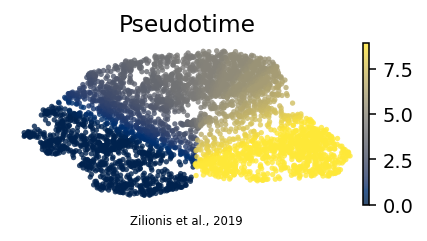

In [10]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
for k in list(sub.uns.get('graph',{}).keys()):
    v = sub.uns['graph'][k]
    if isinstance(v,(list,tuple)):
        try: sub.uns['graph'][k] = np.asarray(v)
        except Exception: pass
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')